## 0. Imports et chargement des images

Taille image 1 : (452, 678, 3)


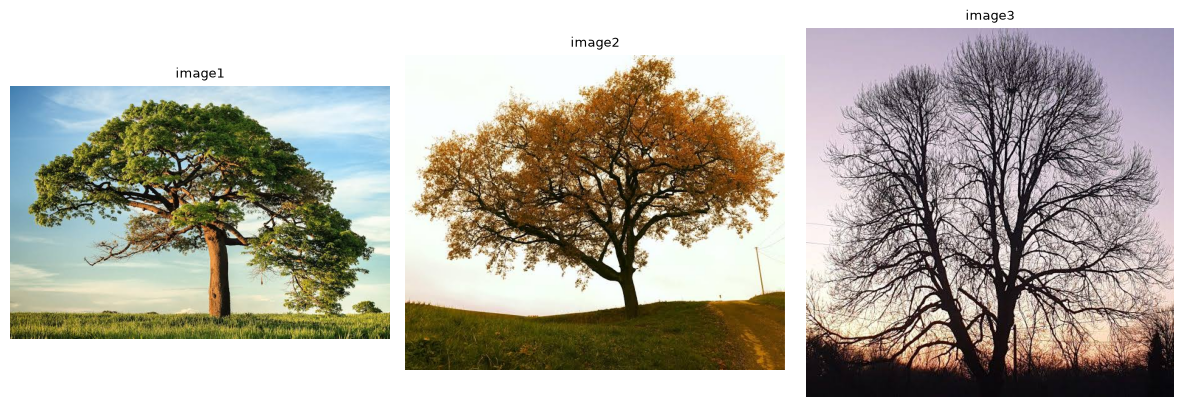

In [2]:
import os
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Les images sont dans le dossier du projet, qui peut être le parent du notebook.
image_names = ("image1.jpg", "image2.jpg", "image3.jpg")
image_dir = Path.cwd()
if not all((image_dir / name).is_file() for name in image_names):
    image_dir = image_dir.parent

paths = [image_dir / name for name in image_names]
images = []
for path in paths:
    image = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Image introuvable ou illisible : {path.resolve()}")
    images.append(image)

img, img2, img3 = images


OUT = "resultats"
os.makedirs(OUT, exist_ok=True)

def save(name, im):
    cv2.imwrite(os.path.join(OUT, name), im)

def show(images, titles=None, cols=3, size=4):
    """Affiche une liste d'images (BGR ou niveaux de gris) avec matplotlib."""
    rows = (len(images) + cols - 1) // cols
    plt.figure(figsize=(size * cols, size * rows))
    for i, im in enumerate(images):
        plt.subplot(rows, cols, i + 1)
        if im.ndim == 2:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        else:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        if titles:
            plt.title(titles[i], fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

print("Taille image 1 :", img.shape)
show([img, img2, img3], ["image1", "image2", "image3"])

## 1. Transformation de l'image

### 1) Modifier la taille de l'image et la sauvegarder

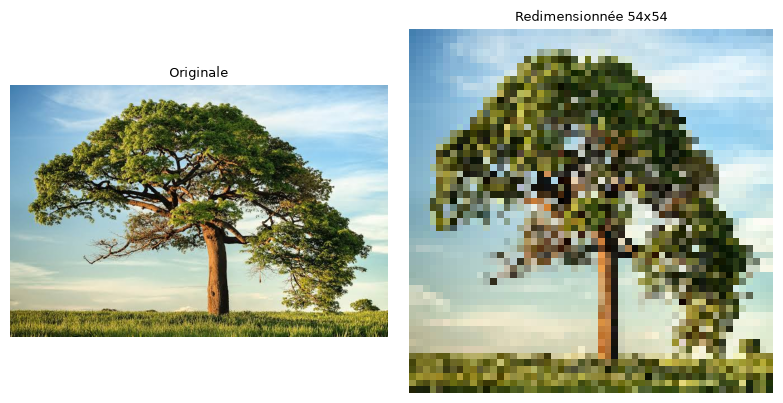

In [3]:
resized = cv2.resize(img, (54, 54))
save("1_resize_54x54.png", resized)
show([img, resized], ["Originale", "Redimensionnée 54x54"], cols=2)

### 2) et 3) Rotations des trois composantes (B, G, R) avec des angles différents, puis sauvegarde

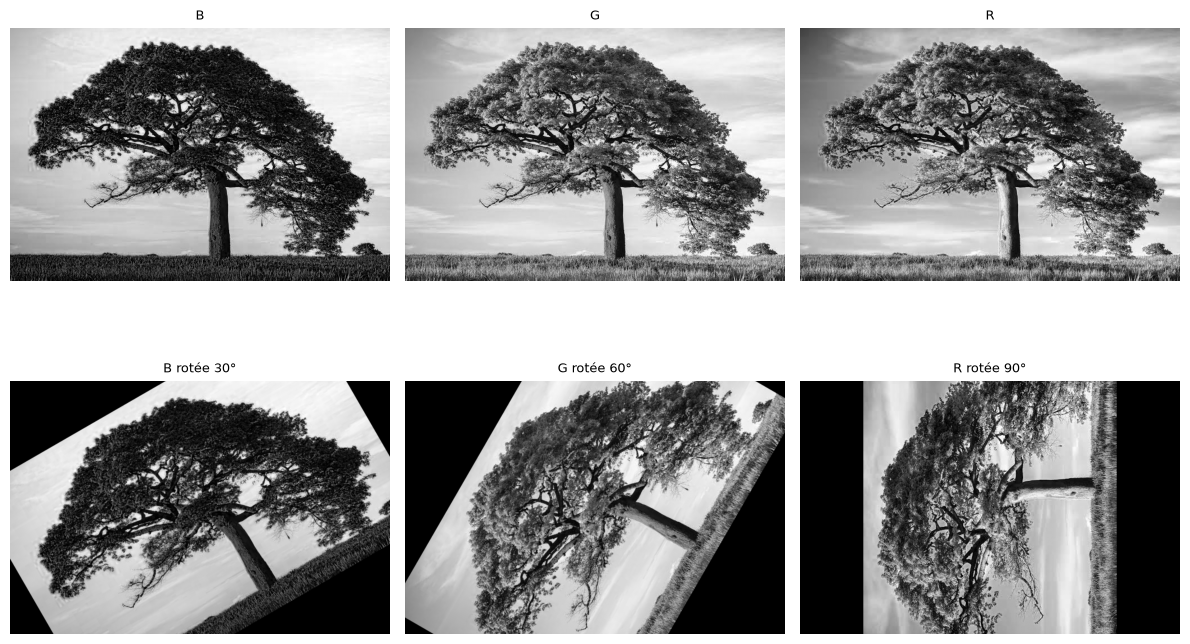

In [4]:
def rotate(im, deg):
    h, w = im.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), deg, 1)
    return cv2.warpAffine(im, M, (w, h))

B, G, R = cv2.split(img)
rot_B, rot_G, rot_R = rotate(B, 30), rotate(G, 60), rotate(R, 90)

save("2_rotation_B_30deg.png", rot_B)
save("2_rotation_G_60deg.png", rot_G)
save("2_rotation_R_90deg.png", rot_R)

show([B, G, R, rot_B, rot_G, rot_R],
     ["B", "G", "R", "B rotée 30°", "G rotée 60°", "R rotée 90°"])

### 4) et 5) Retournement des trois composantes (horizontal et vertical), puis sauvegarde

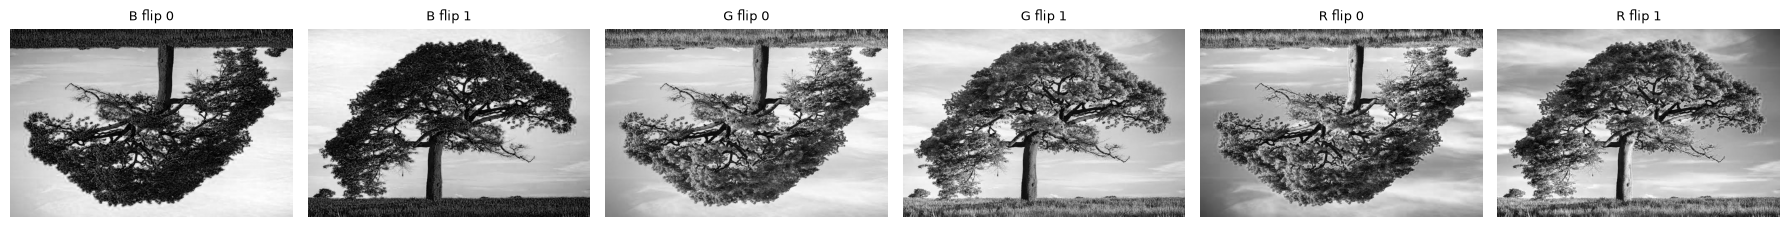

In [5]:
imgs, titres = [], []
for name, comp in [("B", B), ("G", G), ("R", R)]:
    f0 = cv2.flip(comp, 0)   # 0 : autour de l'axe horizontal
    f1 = cv2.flip(comp, 1)   # 1 : autour de l'axe vertical
    save(f"4_flip_{name}_0.png", f0)
    save(f"4_flip_{name}_1.png", f1)
    imgs += [f0, f1]
    titres += [f"{name} flip 0", f"{name} flip 1"]

show(imgs, titres, cols=6, size=3)

### 6) Découper l'image en quelques sous-images (50x50)

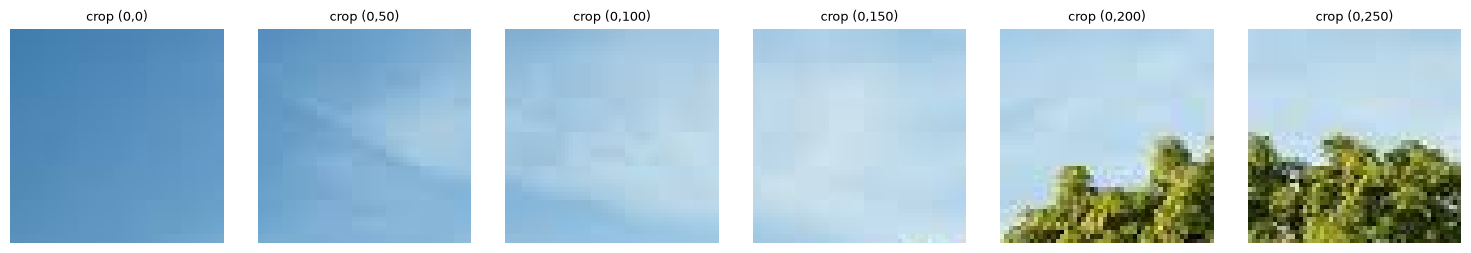

In [6]:
h, w = img.shape[:2]
tiles = []
for x in range(0, h - 49, 50):
    for y in range(0, w - 49, 50):
        tiles.append(((x, y), img[x:x + 50, y:y + 50]))
tiles = tiles[:6]   # on garde quelques sous-images

for (x, y), t in tiles:
    save(f"6_crop_{x}_{y}.png", t)

show([t for _, t in tiles], [f"crop ({x},{y})" for (x, y), _ in tiles], cols=6, size=2.5)

### 7) Modifier et enregistrer la taille des sous-images

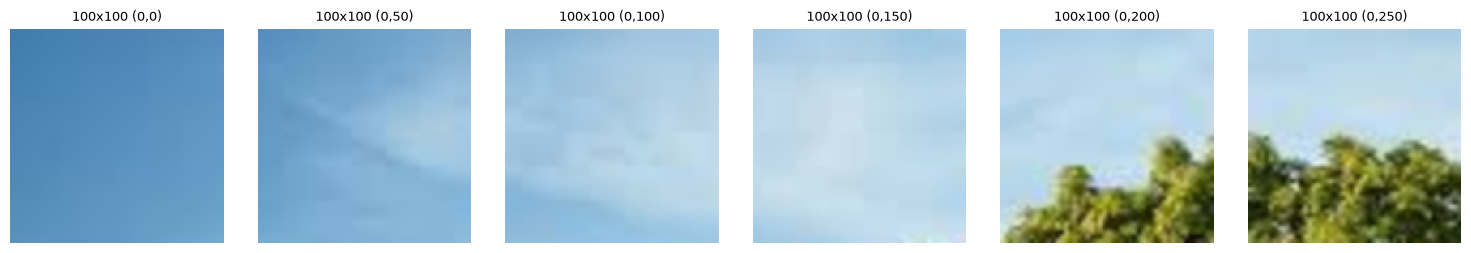

In [7]:
tiles_resized = []
for (x, y), t in tiles:
    r = cv2.resize(t, (100, 100))
    save(f"7_crop_resized_{x}_{y}.png", r)
    tiles_resized.append(r)

show(tiles_resized, [f"100x100 ({x},{y})" for (x, y), _ in tiles], cols=6, size=2.5)

### 8) Cadrer et enregistrer chaque sous-image

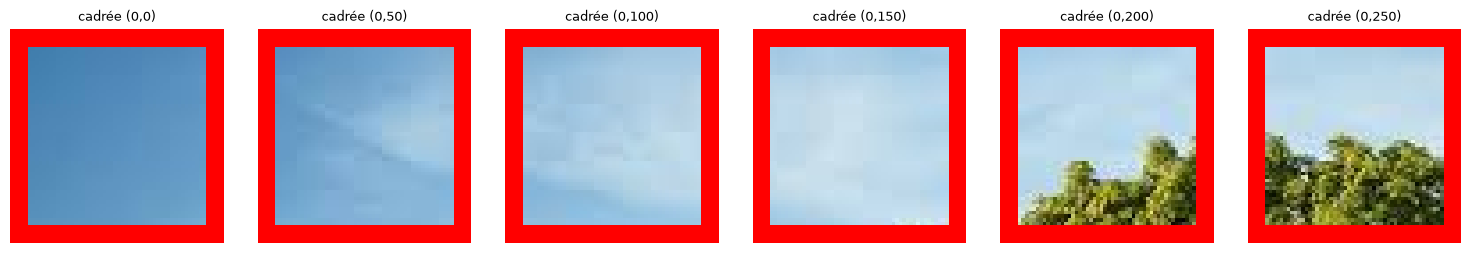

In [8]:
tiles_framed = []
for (x, y), t in tiles:
    framed = cv2.copyMakeBorder(t, 5, 5, 5, 5, cv2.BORDER_CONSTANT, value=(0, 0, 255))
    save(f"8_crop_framed_{x}_{y}.png", framed)
    tiles_framed.append(framed)

show(tiles_framed, [f"cadrée ({x},{y})" for (x, y), _ in tiles], cols=6, size=2.5)

## 2. Égalisation de contraste

### 1) Histogramme (equalizeHist) vs CLAHE : lequel rehausse le plus le contraste ?

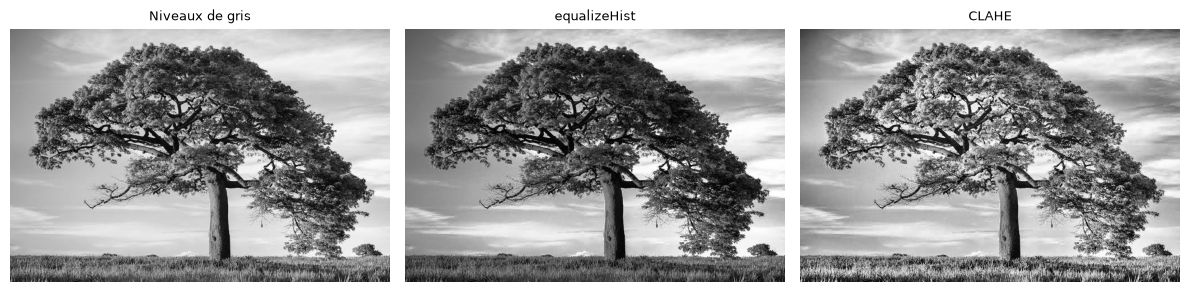

C:\Users\Asus\AppData\Local\Temp\ipykernel_11584\2997482823.py:17: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(im.ravel(), 256, [0, 256])


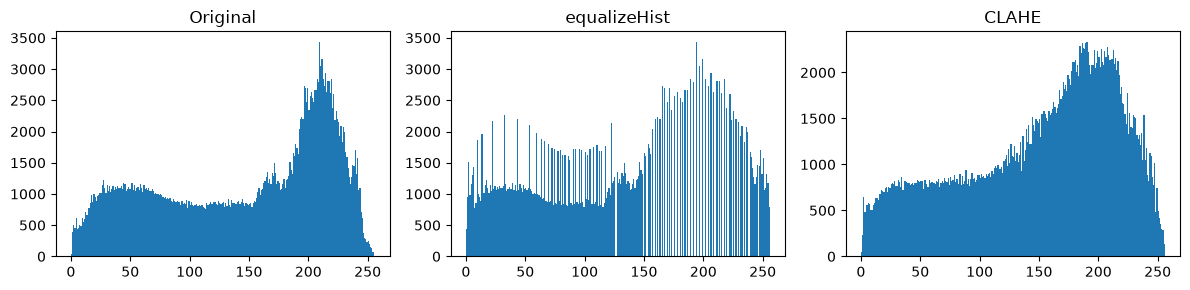

In [9]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

eq = cv2.equalizeHist(gray)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
cl1 = clahe.apply(gray)

save("9_gray.png", gray)
save("9_equalizeHist.png", eq)
save("9_clahe.png", cl1)

show([gray, eq, cl1], ["Niveaux de gris", "equalizeHist", "CLAHE"])

# Histogrammes
plt.figure(figsize=(12, 3))
for i, (im, t) in enumerate([(gray, "Original"), (eq, "equalizeHist"), (cl1, "CLAHE")]):
    plt.subplot(1, 3, i + 1)
    plt.hist(im.ravel(), 256, [0, 256])
    plt.title(t)
plt.tight_layout()
plt.show()

In [10]:
# Mesure du contraste : écart-type des niveaux de gris
print(f"Contraste (écart-type) : original = {gray.std():.1f} | "
      f"equalizeHist = {eq.std():.1f} | CLAHE = {cl1.std():.1f}")

best, best_name = (eq, "equalizeHist") if eq.std() >= cl1.std() else (cl1, "CLAHE")
print("Image la plus contrastée :", best_name)

Contraste (écart-type) : original = 71.6 | equalizeHist = 73.8 | CLAHE = 65.9
Image la plus contrastée : equalizeHist


### 2) Seuillage de l'image la plus contrastée (deux méthodes)

Seuil trouvé par Otsu : 127.0


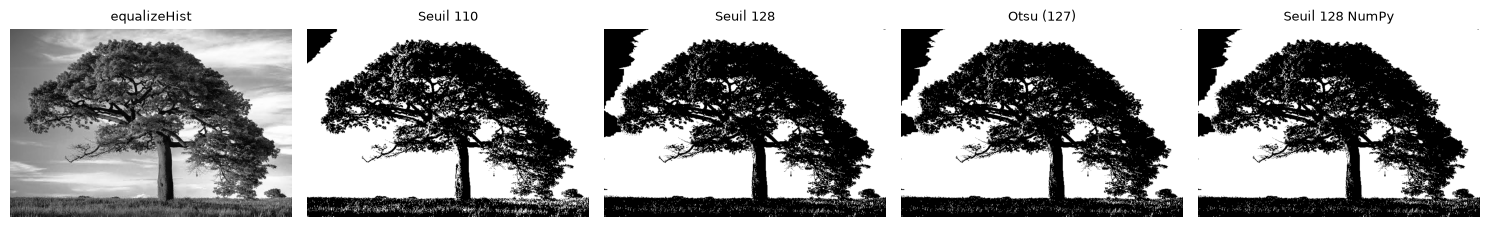

In [11]:
# Méthode 1 : seuil fixe avec cv2.threshold
ret, im_gt = cv2.threshold(best, 110, 255, cv2.THRESH_BINARY)
_, im_128 = cv2.threshold(best, 128, 255, cv2.THRESH_BINARY)

# Méthode 2 : seuil calculé automatiquement (Otsu)
ret_otsu, im_otsu = cv2.threshold(best, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Seuil 128 "à la main" avec NumPy : < 128 -> 0, sinon 255
manual = np.where(best < 128, 0, 255).astype(np.uint8)

save("10_seuil_110.png", im_gt)
save("10_seuil_128.png", im_128)
save("10_seuil_otsu.png", im_otsu)
save("10_seuil_128_numpy.png", manual)

print("Seuil trouvé par Otsu :", ret_otsu)
show([best, im_gt, im_128, im_otsu, manual],
     [best_name, "Seuil 110", "Seuil 128", f"Otsu ({ret_otsu:.0f})", "Seuil 128 NumPy"], cols=5, size=3)

## 3. Opérateurs morphologiques

Éléments structurants : rectangulaire, elliptique, en croix (5x5).

In [12]:
kernels = {
    "RECT":    cv2.getStructuringElement(cv2.MORPH_RECT,    (5, 5)),
    "ELLIPSE": cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)),
    "CROSS":   cv2.getStructuringElement(cv2.MORPH_CROSS,   (5, 5)),
}
for k, v in kernels.items():
    print(k); print(v); print()

RECT
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]

ELLIPSE
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]

CROSS
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]



Noyau RECT


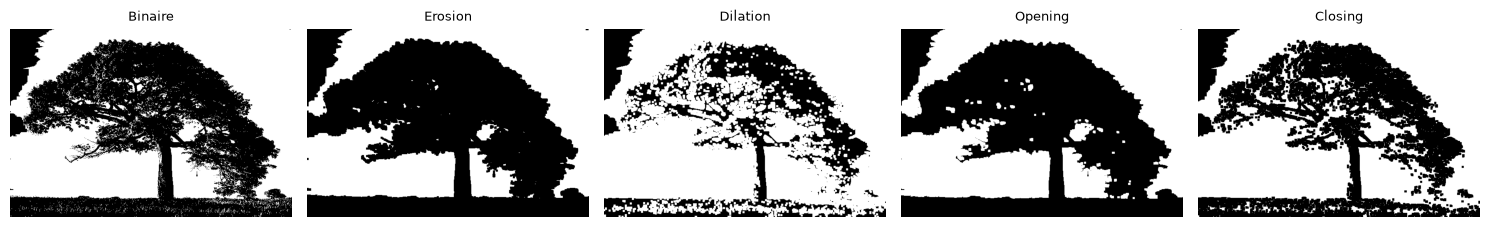

Noyau ELLIPSE


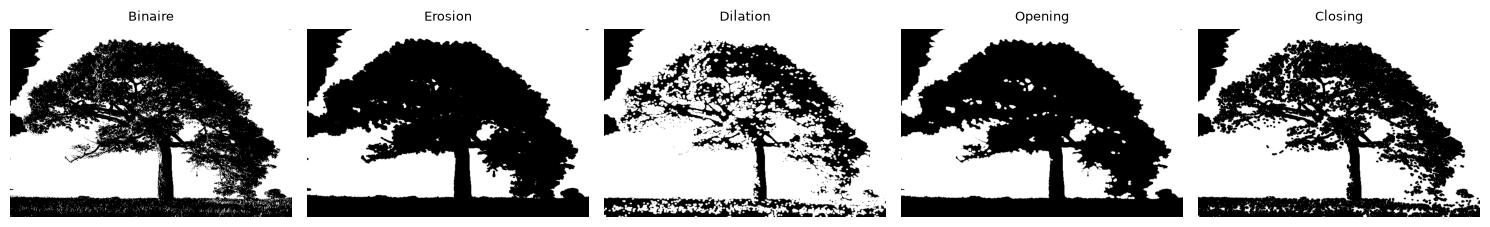

Noyau CROSS


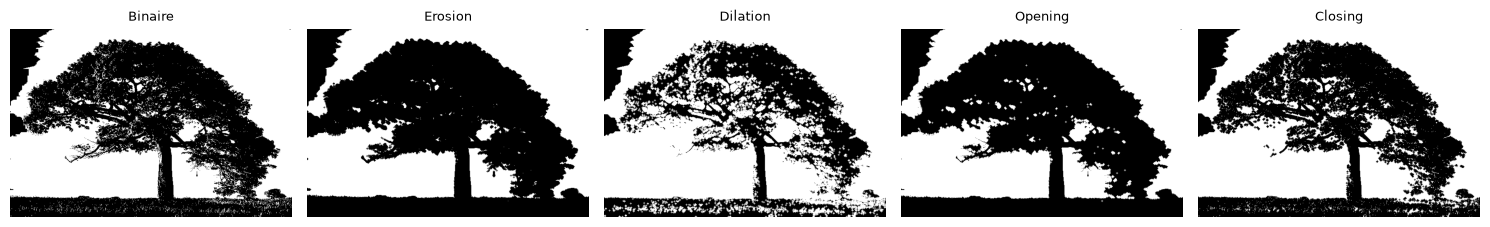

In [13]:
binary = im_otsu   # image binaire issue du seuillage

for kn, k in kernels.items():
    er = cv2.erode(binary, k, iterations=1)
    di = cv2.dilate(binary, k, iterations=1)
    op = cv2.morphologyEx(binary, cv2.MORPH_OPEN, k)
    cl = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, k)
    for nm, r in [("erosion", er), ("dilation", di), ("opening", op), ("closing", cl)]:
        save(f"11_{nm}_{kn}.png", r)
    print(f"Noyau {kn}")
    show([binary, er, di, op, cl],
         ["Binaire", "Erosion", "Dilation", "Opening", "Closing"], cols=5, size=3)

## 4. Addition et soustraction des images

### 1) Image de sommation de deux images différentes

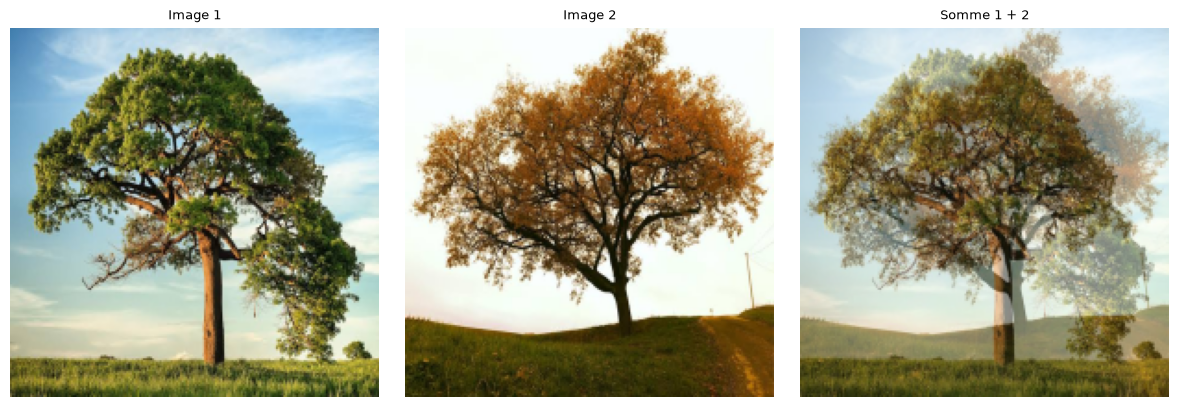

In [14]:
size = (200, 200)
a = cv2.resize(img,  size, interpolation=cv2.INTER_AREA)
b = cv2.resize(img2, size, interpolation=cv2.INTER_AREA)
c = cv2.resize(img3, size, interpolation=cv2.INTER_AREA)

somme1 = cv2.addWeighted(a, 0.5, b, 0.5, 0)
save("12_somme_a_b.png", somme1)
show([a, b, somme1], ["Image 1", "Image 2", "Somme 1 + 2"])

### 2) Deuxième addition avec une autre image

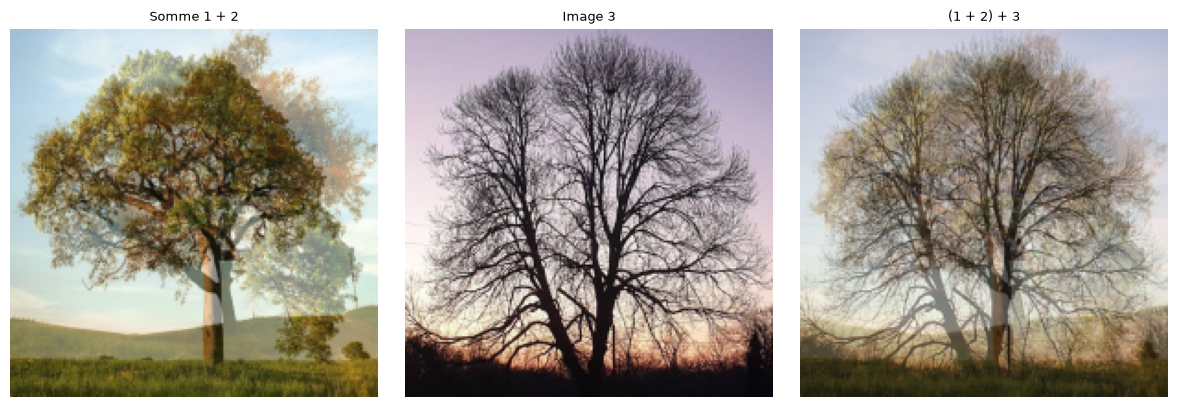

In [15]:
somme2 = cv2.addWeighted(somme1, 0.5, c, 0.5, 0)
save("12_somme_ab_c.png", somme2)
show([somme1, c, somme2], ["Somme 1 + 2", "Image 3", "(1 + 2) + 3"])

### 3) Soustraction entre les images

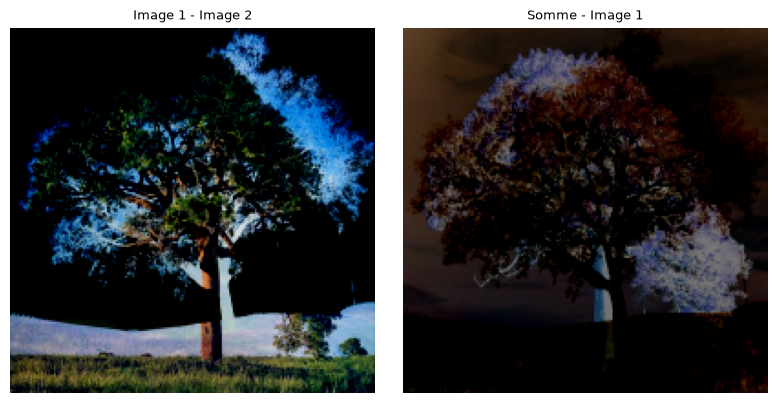

In [16]:
sub1 = cv2.subtract(a, b)
sub2 = cv2.subtract(somme1, a)
save("12_sub_a_moins_b.png", sub1)
save("12_sub_somme_moins_a.png", sub2)
show([sub1, sub2], ["Image 1 - Image 2", "Somme - Image 1"], cols=2)